# Шумоподавление изображений с помощью автоэнкодера

### Motivation
Любой реальный снимок содержит шум: сенсор камеры, слабое освещение, высокий ISO, передача по каналу связи.
Шум портит не только визуальное качество, но и работу следующих этапов CV-конвейера (детекция краёв, ключевых точек, классификация).
Задача проекта — построить **интеллектуальную систему шумоподавления на основе автоэнкодера** и сравнить её с классической фильтрацией (Gaussian filtering).

### Introduction
Существующие подходы:
* **Линейные фильтры** — Gaussian blur, усредняющий фильтр (lesson 3). Простые и быстрые, но размывают края вместе с шумом.
* **Нелинейные фильтры** — median filter (хорошо работает с импульсным шумом), bilateral filter (сохраняет края).
* **Классические продвинутые методы** — Non-Local Means, BM3D: используют повторяющиеся фрагменты изображения.
* **Нейросетевые методы** — denoising autoencoder ([Vincent et al., 2008](https://www.cs.toronto.edu/~larocheh/publications/icml-2008-denoising-autoencoders.pdf)), DnCNN, U-Net. Сеть обучается на парах *(зашумлённое, чистое)* и сама находит, как отделить шум от сигнала.

Основа нашей модели — свёрточный автоэнкодер из официального примера Keras ([Convolutional autoencoder for image denoising](https://keras.io/examples/vision/autoencoder/), MNIST, гауссов шум `0.4`), который в свою очередь основан на статье F. Chollet [Building Autoencoders in Keras](https://blog.keras.io/building-autoencoders-in-keras.html). Мы переносим этот подход на цветные изображения CIFAR-10, добавляем salt & pepper шум и количественно сравниваем результат с классическими фильтрами.

### План ноутбука
* Step 0: Dataset Inspection
* Step 1: Noise Models
* Step 2: Classical Baselines

In [1]:
import cv2
import numpy as np
import tensorflow as tf
from time import time

from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [15, 10]

# Фиксируем seeds для воспроизводимости
from numpy.random import seed
from tensorflow.random import set_seed
seed_value = 1234578790
seed(seed_value)
set_seed(seed_value)

### Step 0: Dataset Inspection

Для обучения используем датасет CIFAR-10 ([link](https://www.cs.toronto.edu/~kriz/cifar.html)) — 60 000 цветных изображений 32×32.
Метки классов нам не нужны: автоэнкодер учится восстанавливать само изображение, поэтому «разметку» (чистое изображение) мы получаем бесплатно.

In [2]:
# Загружаем датасет (метки классов не используем)
(x_train, _), (x_test, _) = tf.keras.datasets.cifar10.load_data()

# Normalization: переводим в [0, 1] и float32 (экономим память)
x_train = x_train.astype(np.float32)/255
x_test = x_test.astype(np.float32)/255

size = x_train.shape[1]

print('Train set:   ', len(x_train), 'samples')
print('Test set:    ', len(x_test), 'samples')
print('Sample dims: ', x_train.shape)

Train set:    50000 samples
Test set:     10000 samples
Sample dims:  (50000, 32, 32, 3)


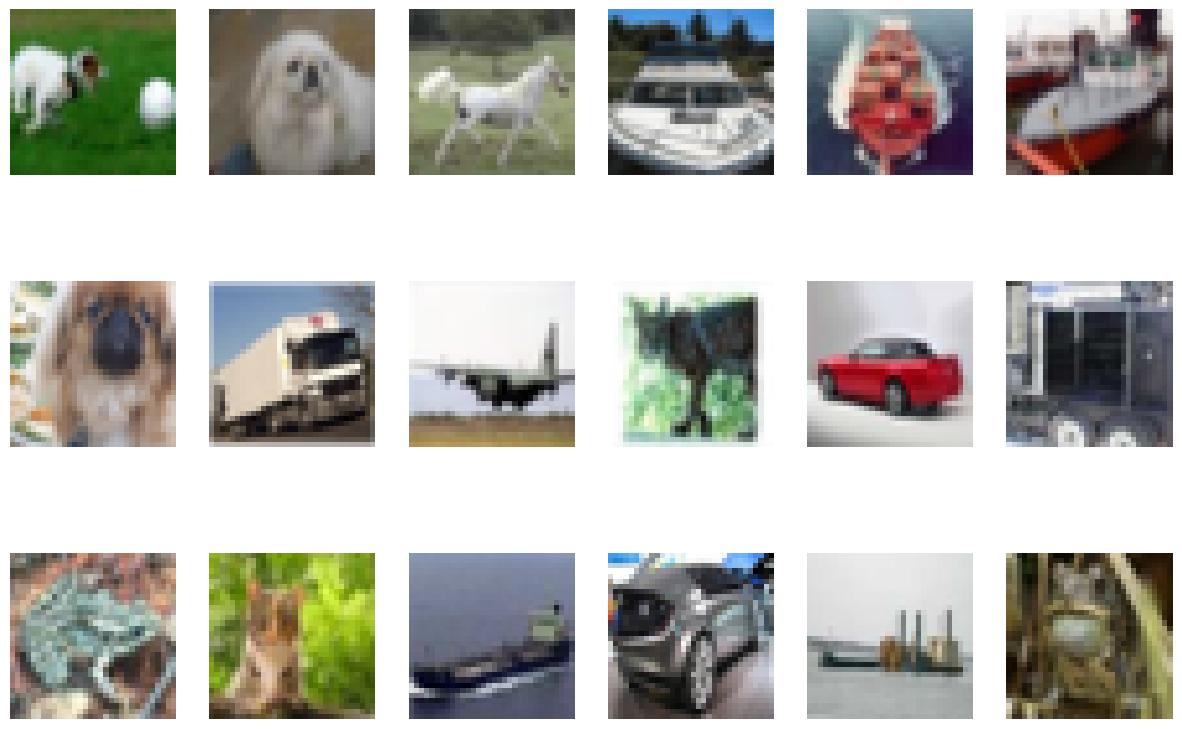

In [3]:
# Показываем случайные примеры (сетка 3x6)
for ii in range(18):
    idx = np.random.randint(len(x_train))
    plt.subplot(3,6,ii+1), plt.imshow(x_train[idx]), plt.axis('off')

### Step 1: Noise Models

Используем два типа шума из лекции (lesson 3):
* **Гауссов шум** — аддитивный: `noisy = img + sigma * N(0, 1)`. Берём `sigma = 0.1`, как в лекции (≈ 25 по шкале 0–255).
* **Salt & Pepper** — импульсный: пиксель с вероятностью `probability = 0.1` становится белым или чёрным.

В лекции salt & pepper реализован через двойной цикл по пикселям. Для 60 000 изображений это слишком медленно, поэтому делаем то же самое векторно — через маски `numpy`.

In [4]:
sigma = 0.1          # СКО гауссова шума
probability = 0.1    # доля пикселей salt & pepper

def add_gaussian_noise(x, sigma=0.1):
    """Аддитивный гауссов шум, результат обрезается в [0, 1]"""
    noisy = x + sigma*np.random.randn(*x.shape)
    return np.clip(noisy, 0, 1).astype(np.float32)

def add_salt_pepper(x, probability=0.1):
    """Импульсный шум: пиксель с вероятностью `probability` становится белым или чёрным"""
    noisy = x.copy()
    # Маска на уровне пикселя: шум одинаковый во всех каналах (как в lesson 3)
    mask = np.random.rand(*x.shape[:-1]) < probability
    salt = np.random.rand(*x.shape[:-1]) < 0.5
    noisy[mask & salt] = 1
    noisy[mask & ~salt] = 0
    return noisy

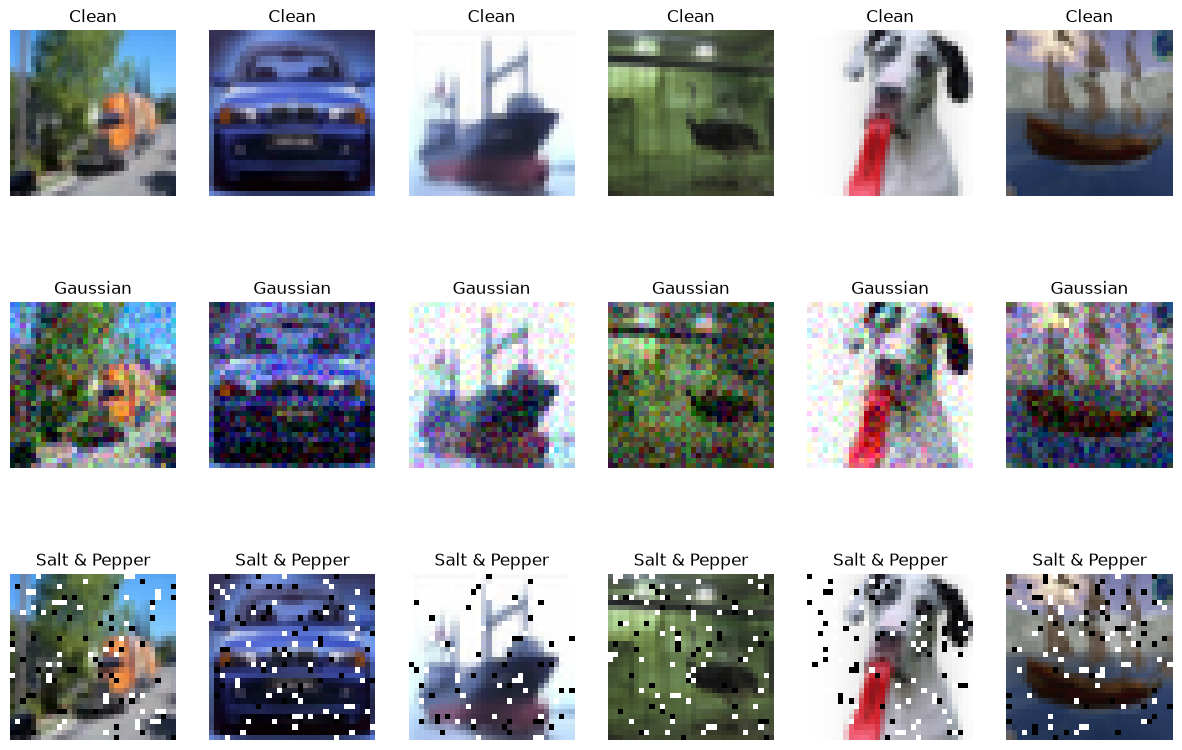

In [5]:
# Зашумлённая тестовая выборка генерируется один раз — все методы сравниваются на одних и тех же данных
x_test_gauss = add_gaussian_noise(x_test, sigma)
x_test_sp = add_salt_pepper(x_test, probability)

# Визуализация: чистое | гауссов шум | salt & pepper
for ii in range(6):
    idx = np.random.randint(len(x_test))
    plt.subplot(3,6,ii+1), plt.imshow(x_test[idx]), plt.axis('off'), plt.title('Clean')
    plt.subplot(3,6,ii+7), plt.imshow(x_test_gauss[idx]), plt.axis('off'), plt.title('Gaussian')
    plt.subplot(3,6,ii+13), plt.imshow(x_test_sp[idx]), plt.axis('off'), plt.title('Salt & Pepper')

### Step 2: Classical Baselines

#### Метрики
Для объективного сравнения используем две стандартные метрики:
* **PSNR** (Peak Signal-to-Noise Ratio): `PSNR = 10 * log10(MAX^2 / MSE)`, для изображений в [0, 1] `MAX = 1`. Измеряется в dB, чем больше — тем лучше.
* **SSIM** (Structural Similarity) — сравнивает яркость, контраст и структуру локальных окон. Значение в [0, 1], чем ближе к 1 — тем лучше. Лучше, чем PSNR, соответствует восприятию человека.

In [6]:
def psnr(clean, test):
    """PSNR в dB для одного изображения в диапазоне [0, 1] (формула выше)"""
    mse = np.mean((clean.astype(np.float64) - test.astype(np.float64))**2)
    return 10*np.log10(1.0/mse)

def evaluate(clean_set, test_set):
    """Средние PSNR и SSIM по набору изображений.
    Для тысяч изображений считаем векторно через tf.image — это в сотни раз быстрее цикла."""
    p = tf.image.psnr(clean_set, test_set, max_val=1.0)
    s = tf.image.ssim(clean_set, test_set, max_val=1.0)
    return float(tf.reduce_mean(p)), float(tf.reduce_mean(s))

# Проверка: наша формула PSNR совпадает с tf.image.psnr
print(psnr(x_test[0], x_test_gauss[0]), float(tf.image.psnr(x_test[0], x_test_gauss[0], max_val=1.0)))

20.084225749469972 20.084224700927734


#### Фильтры
Классические фильтры из lesson 3. OpenCV работает с `uint8`, поэтому перед фильтрацией переводим изображения в [0, 255], а после — обратно в [0, 1].

In [7]:
def to_uint8(x):
    return np.clip(255*x, 0, 255).round().astype(np.uint8)

def to_float(x):
    return x.astype(np.float32)/255

def gaussian_filter(images, ksize=5, sigma=5):
    return np.array([to_float(cv2.GaussianBlur(to_uint8(img), ksize=(ksize, ksize), sigmaX=sigma)) for img in images])

def median_filter(images, ksize=3):
    return np.array([to_float(cv2.medianBlur(to_uint8(img), ksize=ksize)) for img in images])

def bilateral_filter(images, d=5, sigma_color=75, sigma_space=75):
    return np.array([to_float(cv2.bilateralFilter(to_uint8(img), d=d, sigmaColor=sigma_color, sigmaSpace=sigma_space)) for img in images])

#### Подбор параметров
Параметры из лекции (`ksize=(5,5), sigmaX=5`) подобраны для фото 768×512. Для изображений 32×32 такое размытие слишком сильное.
Чтобы сравнение с автоэнкодером было честным, подбираем параметры каждого фильтра по PSNR на **валидационной** выборке (последние 1000 изображений train), а не на тесте.

In [8]:
x_val = x_train[-1000:]
x_val_gauss = add_gaussian_noise(x_val, sigma)
x_val_sp = add_salt_pepper(x_val, probability)

# Сетки параметров для каждого фильтра
grids = {
    'gaussian':  [dict(ksize=k, sigma=s) for k in [3, 5, 7] for s in [0.5, 1, 2, 5]],
    'median':    [dict(ksize=k) for k in [3, 5]],
    'bilateral': [dict(d=d, sigma_color=c) for d in [3, 5, 7] for c in [50, 100, 150, 200]],
}
filters = {'gaussian': gaussian_filter, 'median': median_filter, 'bilateral': bilateral_filter}

best_params = {}
for noise_name, x_val_noisy in [('gaussian', x_val_gauss), ('salt_pepper', x_val_sp)]:
    for filter_name, grid in grids.items():
        scores = [evaluate(x_val, filters[filter_name](x_val_noisy, **params))[0] for params in grid]
        best = int(np.argmax(scores))
        best_params[(noise_name, filter_name)] = grid[best]
        print(f'{noise_name:12s} {filter_name:10s} best: {grid[best]}  PSNR = {scores[best]:.2f} dB')

gaussian     gaussian   best: {'ksize': 3, 'sigma': 1}  PSNR = 24.73 dB


gaussian     median     best: {'ksize': 3}  PSNR = 23.77 dB


gaussian     bilateral  best: {'d': 5, 'sigma_color': 100}  PSNR = 26.01 dB


salt_pepper  gaussian   best: {'ksize': 5, 'sigma': 1}  PSNR = 21.71 dB


salt_pepper  median     best: {'ksize': 3}  PSNR = 26.01 dB


salt_pepper  bilateral  best: {'d': 7, 'sigma_color': 200}  PSNR = 17.62 dB


#### Оценка на тестовой выборке
Сравниваем на всех 10 000 тестовых изображениях:
* **Noisy** — изображение без обработки (нижняя граница),
* **Gaussian (lecture)** — параметры из лекции,
* **Gaussian / Median / Bilateral** — с подобранными параметрами.

In [9]:
results = {}
test_sets = {'gaussian': x_test_gauss, 'salt_pepper': x_test_sp}

for noise_name, x_noisy in test_sets.items():
    results[(noise_name, 'Noisy')] = evaluate(x_test, x_noisy)
    results[(noise_name, 'Gaussian (lecture)')] = evaluate(x_test, gaussian_filter(x_noisy, ksize=5, sigma=5))
    for filter_name in filters:
        params = best_params[(noise_name, filter_name)]
        results[(noise_name, filter_name.capitalize())] = evaluate(x_test, filters[filter_name](x_noisy, **params))

def print_results(results):
    print(f'{"Noise":12s} {"Method":20s} {"PSNR, dB":>9s} {"SSIM":>7s}')
    for (noise_name, method), (p, s) in results.items():
        print(f'{noise_name:12s} {method:20s} {p:9.2f} {s:7.3f}')

print_results(results)

Noise        Method                PSNR, dB    SSIM
gaussian     Noisy                    20.33   0.654
gaussian     Gaussian (lecture)       21.54   0.615
gaussian     Gaussian                 24.71   0.812
gaussian     Median                   23.74   0.758
gaussian     Bilateral                26.00   0.848
salt_pepper  Noisy                    15.08   0.465
salt_pepper  Gaussian (lecture)       20.46   0.560
salt_pepper  Gaussian                 21.71   0.689
salt_pepper  Median                   25.98   0.865
salt_pepper  Bilateral                17.65   0.499


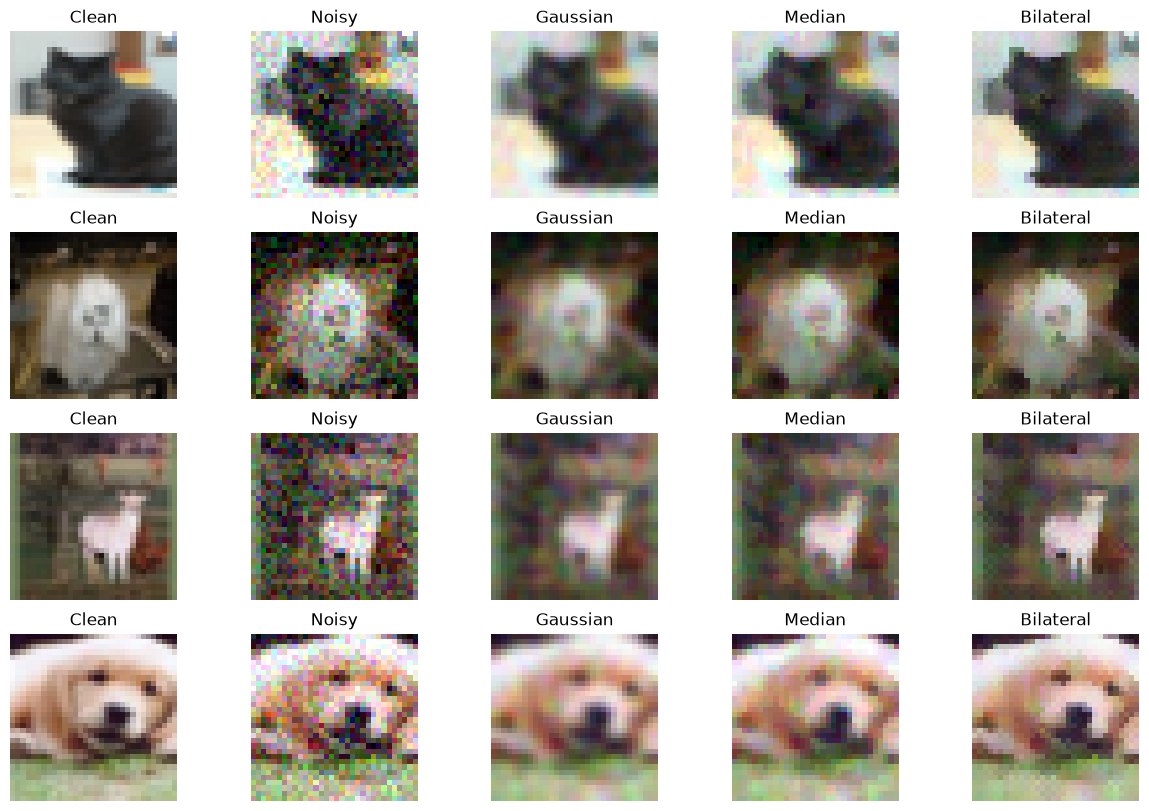

In [10]:
# Визуальное сравнение: Clean | Noisy | Gaussian | Median | Bilateral
def show_baselines(x_noisy, noise_name, indices):
    methods = ['Clean', 'Noisy', 'Gaussian', 'Median', 'Bilateral']
    for row, idx in enumerate(indices):
        img = x_noisy[idx:idx+1]
        outs = [x_test[idx], x_noisy[idx]] + [filters[f](img, **best_params[(noise_name, f)])[0] for f in filters]
        for col, (title, out) in enumerate(zip(methods, outs)):
            plt.subplot(len(indices), len(methods), row*len(methods) + col + 1)
            plt.imshow(out), plt.axis('off'), plt.title(title)

indices = np.random.randint(len(x_test), size=4)
show_baselines(x_test_gauss, 'gaussian', indices)

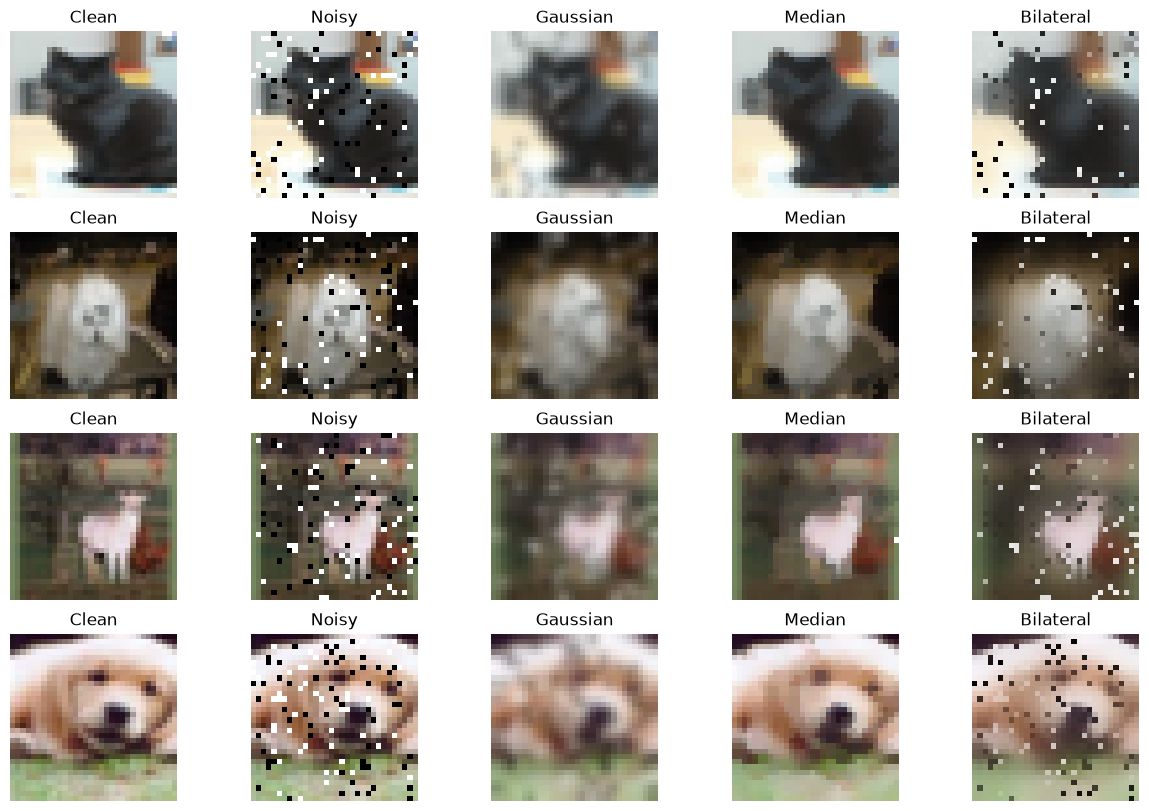

In [11]:
show_baselines(x_test_sp, 'salt_pepper', indices)

#### Выводы по классическим фильтрам
* **Параметры из лекции** (`5×5, sigma=5`) для маленьких изображений 32×32 размывают слишком сильно: SSIM даже ниже, чем у зашумлённого изображения. Подбор параметров обязателен для честного сравнения.
* **Гауссов шум:** лучший классический метод — **bilateral filter**, он сглаживает шум и частично сохраняет края. Gaussian blur убирает шум вместе с деталями.
* **Salt & Pepper:** **median filter** — вне конкуренции, как и показано в лекции. Gaussian и bilateral фильтры плохо работают с импульсным шумом: они «размазывают» выбросы по соседним пикселям.
* Ни один фильтр не универсален: для каждого типа шума нужен свой метод и свои параметры. Это главная мотивация для обучаемого подхода — **автоэнкодера**, который сам подстраивается под тип шума по обучающим данным.